<a href="https://colab.research.google.com/github/sahferr/my_colab/blob/main/preparacao_dados_projeto_c_endoteliais.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Processamento de imagem
Prepara as imagens de microscopia especular para o treino da U-Net.
Base: material do Prof. Cesar Augusto Cardoso Caetano (apostila de R. Antonello) + transformada de Fourier.
Os centros anotados nos `.txt` são usados como gabarito para validar o processamento.

# **Criação do drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
RAIZ = Path('/content/drive/MyDrive/endotelio')
DATASET = RAIZ / 'dataset'          # ajuste para o seu caminho
PROCESSADO = RAIZ / 'processado'
MODELOS = RAIZ / 'modelos'
RESULTADOS = RAIZ / 'resultados'
SEED = 42

for pasta in (PROCESSADO, MODELOS, RESULTADOS):
    pasta.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


# **libs**

In [ ]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree, Delaunay
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from skimage.feature import peak_local_max
from skimage.feature import peak_local_max
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from scipy.spatial import Delaunay
from sklearn.model_selection import train_test_split

#**Leitura das imagens**

In [ ]:
from google.colab import files
import zipfile, io

destino = DATASET / 'train'
destino.mkdir(parents=True, exist_ok=True)

enviados = files.upload()
for nome, conteudo in enviados.items():
    if nome.endswith('.zip'):
        with zipfile.ZipFile(io.BytesIO(conteudo)) as z:
            z.extractall(destino)
    else:
        (destino / nome).write_bytes(conteudo)
print('ok')

Saving 72385.txt to 72385.txt
Saving 72385.tiff to 72385.tiff
Saving 72384.txt to 72384.txt
Saving 72384.tiff to 72384.tiff
Saving 72383.txt to 72383.txt
Saving 72383.tiff to 72383.tiff
Saving 72382.txt to 72382.txt
Saving 72382.tiff to 72382.tiff
Saving 72381.txt to 72381.txt
Saving 72381.tiff to 72381.tiff
Saving 72380.txt to 72380.txt
Saving 72380.tiff to 72380.tiff
Saving 72379.txt to 72379.txt
Saving 72379.tiff to 72379.tiff
Saving 72378.txt to 72378.txt
Saving 72378.tiff to 72378.tiff
Saving 72377.txt to 72377.txt
Saving 72377.tiff to 72377.tiff
Saving 72376.txt to 72376.txt
Saving 72376.tiff to 72376.tiff
Saving 72375.txt to 72375.txt
Saving 72375.tiff to 72375.tiff
Saving 72374.txt to 72374.txt
Saving 72374.tiff to 72374.tiff
Saving 72373.txt to 72373.txt
Saving 72373.tiff to 72373.tiff
Saving 72372.txt to 72372.txt
Saving 72372.tiff to 72372.tiff
Saving 72371.txt to 72371.txt
Saving 72371.tiff to 72371.tiff
Saving 72370.txt to 72370.txt
Saving 72370.tiff to 72370.tiff
Saving 7

- listar_pares: acha os arquivos
- carregar_imagem: abre a imagem (vira números)
- ler_centros: abre o .txt (vira tabela)
- resumir_par:confere os dados em números
- mostrar_centros: confere os dados no olho

In [ ]:
def listar_pares(pasta, ext='.png'):
    pares = []
    for img in sorted(pasta.rglob(f'*{ext}')):
        txt = img.with_suffix('.txt')
        if txt.exists():
            pares.append((img, txt))
    return pares

pares = listar_pares(RAIZ, ext='.tiff')
print(len(pares), 'pares')
print(pares[0] if pares else 'nenhum par encontrado')

def carregar_imagem(caminho):
    return cv2.imread(str(caminho), cv2.IMREAD_GRAYSCALE)

def ler_centros(caminho):
    return pd.read_csv(caminho, sep=r'\s+')


770 pares
(PosixPath('/content/drive/MyDrive/endotelio/dataset/train/71866 (1).tiff'), PosixPath('/content/drive/MyDrive/endotelio/dataset/train/71866 (1).txt'))


,imagem,altura,largura,n_centros,tags
0,71866 (1).tiff,477,260,266,[0]
1,71866.tiff,477,260,266,[0]
2,71867 (1).tiff,477,260,77,[0]
3,71867.tiff,477,260,77,[0]
4,71868 (1).tiff,477,260,187,[0]


,altura,largura,n_centros
count,770.0,770.0,770.000000
mean,477.0,260.0,109.472727
std,0.0,0.0,87.110888
min,477.0,260.0,0.000000
25%,477.0,260.0,40.000000
50%,477.0,260.0,96.000000
75%,477.0,260.0,172.000000
max,477.0,260.0,372.000000


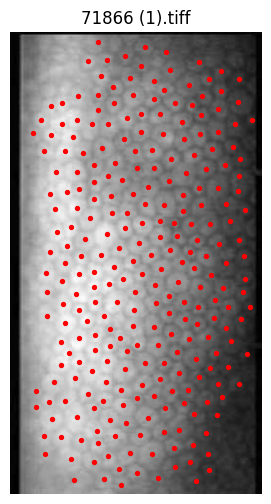

In [ ]:
def resumir_par(img_path, txt_path):
    img = carregar_imagem(img_path)
    centros = ler_centros(txt_path)
    return {'imagem': img_path.name,
            'altura': img.shape[0], 'largura': img.shape[1],
            'n_centros': len(centros),
            'tags': sorted(centros['tag'].unique())}

resumo = pd.DataFrame([resumir_par(i, t) for i, t in pares])
display(resumo.head())
display(resumo[['altura', 'largura', 'n_centros']].describe())

def mostrar_centros(img, centros, titulo=''):
    plt.figure(figsize=(6, 6))
    plt.imshow(img, cmap='gray')
    plt.scatter(centros['x'], centros['y'], s=8, c='red')
    plt.title(titulo)
    plt.axis('off')
    plt.show()

img_path, txt_path = pares[0]
mostrar_centros(carregar_imagem(img_path), ler_centros(txt_path), img_path.name)

#**Medir espaço das imagens, suavização, equalização e fourier**

In [ ]:
def espacamento_medio(centros):
    pts = centros[['x', 'y']].to_numpy(float)
    dist, _ = cKDTree(pts).query(pts, k=2)
    return float(np.median(dist[:, 1]))

print('espaçamento da imagem 0:', round(espacamento_medio(ler_centros(pares[0][1])), 1), 'px')



espaçamento da imagem 0: 16.8 px


O problema: a imagem tem um granulado, pequenos pontos claros e escuros aleatórios. Isso é ruído do microscópio, e atrapalha enxergar onde termina uma célula e começa a outra.

A ideia: cada pixel é trocado por uma mistura dele com os vizinhos. O granulado, que é aleatório, se cancela, e o que é estrutura de verdade (a célula e a borda) continua.

Os 4 filtros:

média: soma os vizinhos por igual, e por isso borra tudo, inclusive as bordas;
gaussiano: dá mais peso aos vizinhos mais próximos, e borra um pouco menos;
mediana: pega o valor do meio dos vizinhos, o que ignora pontos fora do padrão;
bilateral: só mistura vizinhos de brilho parecido, então não mistura a borda escura com o interior claro e preserva as bordas.

Equalização de histograma (cap. 6 da apostila), só a ideia.

O histograma é uma contagem de quantos pixels a imagem tem de cada brilho, de 0 (preto) a 255 (branco).

O problema: nas suas imagens, quase todos os pixels estão numa faixa estreita de cinzas. As células e as bordas têm brilhos muito parecidos, e por isso é difícil separá-las.

A ideia: a equalização estica essa faixa estreita para ocupar de 0 a 255. Cinzas que eram quase iguais passam a ficar bem diferentes, e a borda escura se destaca do interior claro.

É como aumentar o contraste de uma foto apagada.

A limitação: ela trata a imagem inteira de uma vez. Se um lado é claro e o outro escuro, ela continua clara de um lado e escura do outro, só que com mais contraste. Por isso a equalização sozinha não resolve a luz desigual, e é aí que entra o Fourier.

Transformada de Fourier

A analogia é o som. Uma música mistura sons graves e agudos. Um equalizador de som separa essas faixas, e você pode aumentar ou cortar cada uma.

Com a imagem é igual. O Fourier separa a imagem em “faixas” de variação:

Variação lenta (grave): a luz que vai mudando aos poucos de um lado para o outro. É a iluminação desigual.
Variação média: o padrão que se repete a cada ~17 px. São as células.
Variação rápida (agudo): pontinhos que mudam de pixel para pixel. É o ruído.

O filtro passa-banda funciona como um equalizador que:

corta o grave, e a luz desigual some;
corta o agudo, e o ruído some;
mantém só a faixa das células.

O espaçamento de 17 px diz ao filtro qual faixa manter. Por isso medimos ele antes.

Diferença das outras técnicas:

a suavização só tira o ruído;
a equalização só aumenta o contraste;
o Fourier tira o ruído e a luz desigual de uma vez.

In [ ]:
def media(img, esp):
    k = int(esp / 4) | 1
    return cv2.blur(img, (k, k))

def gaussiano(img, esp):
    return cv2.GaussianBlur(img, (0, 0), esp / 6)

def mediana(img, esp):
    k = int(esp / 4) | 1
    return cv2.medianBlur(img, k)

def bilateral(img, esp):
    return cv2.bilateralFilter(img, int(esp / 3) | 1, 50, esp / 4)

def equalizado(img, esp):
    return cv2.equalizeHist(img)

def gauss_equalizado(img, esp):
    return cv2.equalizeHist(gaussiano(img, esp))

def fourier_passa_banda(img, esp):
    h, w = img.shape
    F = np.fft.fftshift(np.fft.fft2(img.astype(float)))
    yy, xx = np.ogrid[:h, :w]
    r = np.hypot((yy - h / 2) / h, (xx - w / 2) / w)
    f0 = 1 / esp
    filtro = (1 - np.exp(-(r / (0.5 * f0)) ** 2)) * np.exp(-(r / (2 * f0)) ** 2)
    out = np.real(np.fft.ifft2(np.fft.ifftshift(F * filtro)))
    return cv2.normalize(out, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

METODOS = {
    'original':          lambda img, esp: img,
    'media (cap7)':      media,
    'gaussiano (cap7)':  gaussiano,
    'mediana (cap7)':    mediana,
    'bilateral (cap7)':  bilateral,
    'equalizado (cap6)': equalizado,
    'gauss+equal (6+7)': gauss_equalizado,
    'fourier':           fourier_passa_banda,
}

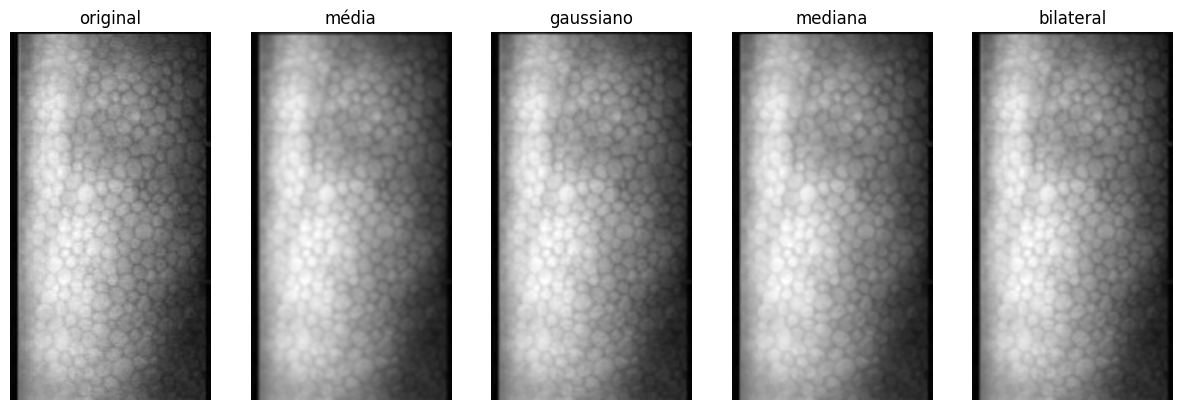

espaçamento: 16.8 px | k = 5


In [ ]:
img = carregar_imagem(pares[0][0])
esp = espacamento_medio(ler_centros(pares[0][1]))
k = int(esp / 4) | 1          # tamanho do filtro (ímpar), a partir do espaçamento

suavizadas = {
    'original':  img,
    'média':     cv2.blur(img, (k, k)),
    'gaussiano': cv2.GaussianBlur(img, (k, k), 0),
    'mediana':   cv2.medianBlur(img, k),
    'bilateral': cv2.bilateralFilter(img, k, 50, 50),
}

fig, eixos = plt.subplots(1, 5, figsize=(15, 6))
for ax, (nome, im) in zip(eixos, suavizadas.items()):
    ax.imshow(im, cmap='gray')
    ax.set_title(nome)
    ax.axis('off')
plt.show()
print('espaçamento:', round(esp, 1), 'px | k =', k)

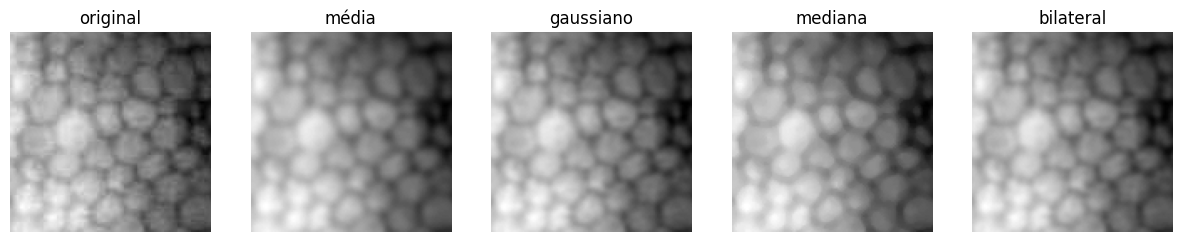

In [ ]:
y0, x0, lado = 150, 60, 120     # recorte de 120×120 px

fig, eixos = plt.subplots(1, 5, figsize=(15, 3.5))
for ax, (nome, im) in zip(eixos, suavizadas.items()):
    ax.imshow(im[y0:y0+lado, x0:x0+lado], cmap='gray')
    ax.set_title(nome)
    ax.axis('off')
plt.show()

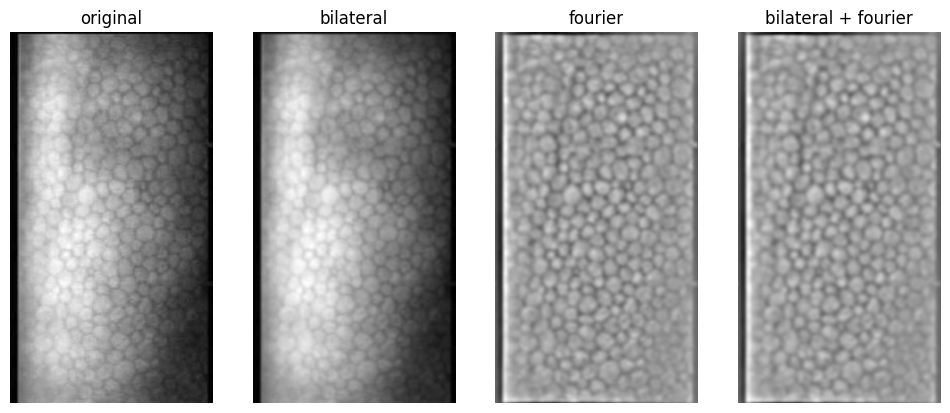

In [ ]:
img = carregar_imagem(pares[0][0])
esp = espacamento_medio(ler_centros(pares[0][1]))

versoes = {
    'original':            img,
    'bilateral':           bilateral(img, esp),
    'fourier':             fourier_passa_banda(img, esp),
    'bilateral + fourier': fourier_passa_banda(bilateral(img, esp), esp),
}

fig, eixos = plt.subplots(1, 4, figsize=(12, 6))
for ax, (nome, im) in zip(eixos, versoes.items()):
    ax.imshow(im, cmap='gray')
    ax.set_title(nome)
    ax.axis('off')
plt.show()

O Fourier funcionou: a luz ficou uniforme. As células do lado direito, que estavam escuras, agora aparecem tão bem quanto as do lado esquerdo.

O que dá para observar:

O ganho: a imagem toda tem o mesmo brilho, e o padrão de favo aparece de ponta a ponta.
O custo: a imagem ficou mais acinzentada, com menos contraste. Também surgiu uma faixa clara nas bordas da imagem, um efeito comum do Fourier nos limites.
Bilateral + Fourier
só Fourier: quase iguais. A bilateral deixa um pouco mais liso, mas a diferença é pequena.

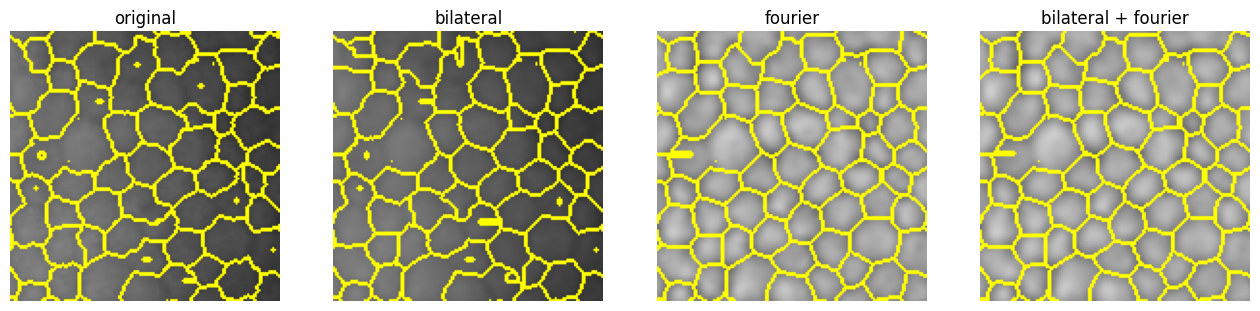

In [ ]:
from skimage.segmentation import watershed, mark_boundaries

def contornos_watershed(im, centros, esp):
    pts = centros[['x', 'y']].to_numpy(int)
    marcadores = np.zeros(im.shape, int)
    regiao = np.zeros(im.shape, np.uint8)
    for i, (x, y) in enumerate(pts, start=1):
        marcadores[y, x] = i
        cv2.circle(regiao, (int(x), int(y)), int(esp * 0.8), 1, -1)
    return watershed(255 - im, marcadores, mask=regiao.astype(bool))

centros = ler_centros(pares[0][1])
y0, x0, lado = 150, 60, 140

fig, eixos = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (nome, im) in zip(eixos, versoes.items()):
    rotulos = contornos_watershed(im, centros, esp)
    ax.imshow(mark_boundaries(im, rotulos)[y0:y0+lado, x0:x0+lado])
    ax.set_title(nome)
    ax.axis('off')
plt.show()

In [ ]:

def contraste(im, centros):
    pts = centros[['x', 'y']].to_numpy(float)
    tri = Delaunay(pts)
    arestas = {tuple(sorted((s[i], s[j]))) for s in tri.simplices for i, j in ((0,1),(1,2),(0,2))}
    bordas = np.array([(pts[a] + pts[b]) / 2 for a, b in arestas])
    pega = lambda p: im[p[:,1].astype(int).clip(0, im.shape[0]-1), p[:,0].astype(int).clip(0, im.shape[1]-1)].astype(float)
    return (pega(pts).mean() - pega(bordas).mean()) / (im.std() + 1e-9)

def f1_deteccao(im, centros, esp):
    achados = peak_local_max(cv2.GaussianBlur(im, (0, 0), esp / 6), min_distance=int(esp / 2))[:, ::-1]
    certos = centros[['x', 'y']].to_numpy(float)
    if len(achados) == 0:
        return 0.0
    dist = cdist(achados, certos)
    lin, col = linear_sum_assignment(dist)
    acertos = (dist[lin, col] <= esp / 2).sum()
    return 2 * acertos / (len(achados) + len(certos))

combinacoes = {
    'original':            lambda im, esp: im,
    'bilateral':           lambda im, esp: bilateral(im, esp),
    'fourier':             lambda im, esp: fourier_passa_banda(im, esp),
    'bilateral + fourier': lambda im, esp: fourier_passa_banda(bilateral(im, esp), esp),
    'fourier + equalizado':lambda im, esp: cv2.equalizeHist(fourier_passa_banda(im, esp)),
}

linhas = []
for img_path, txt_path in pares:
    if ' (' in img_path.name:          # ignora as cópias
        continue
    centros = ler_centros(txt_path)
    if len(centros) < 3:
        continue
    im, esp = carregar_imagem(img_path), espacamento_medio(centros)
    for nome, f in combinacoes.items():
        proc = f(im, esp)
        linhas.append({'versao': nome, 'contraste': contraste(proc, centros), 'f1': f1_deteccao(proc, centros, esp)})

tabela = pd.DataFrame(linhas).groupby('versao').mean().sort_values('f1', ascending=False)
display(tabela.round(3))

,contraste,f1
versao,,
fourier,0.489,0.451
bilateral + fourier,0.474,0.440
fourier + equalizado,1.015,0.427
original,0.108,0.272
bilateral,0.098,0.265


O Fourier é o que faz diferença. As três versões com Fourier têm contraste 4 a 10 vezes maior e F1 cerca de 65% maior que a original.
A bilateral não ajuda. Sozinha fica igual à original, e junto com o Fourier não acrescenta nada.
A equalização faz uma troca. Ela dobra o contraste (as bordas ficam mais marcadas), mas o F1 cai um pouco, porque ela também realça um pouco do ruído.

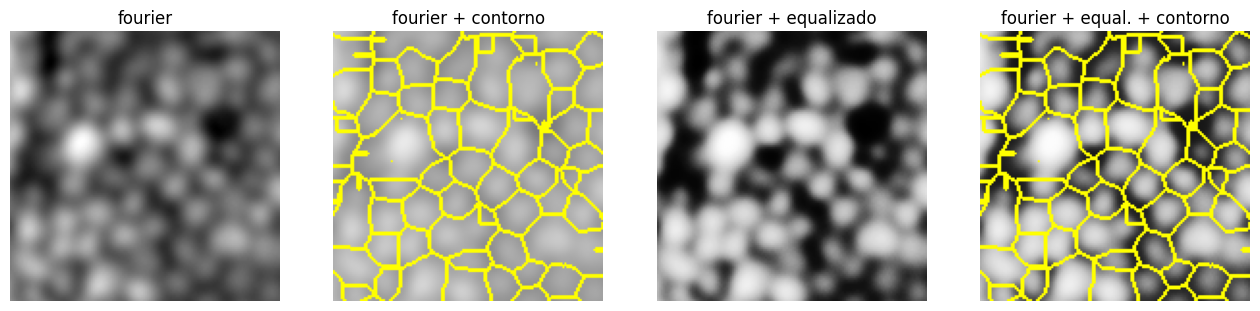

In [ ]:
f  = fourier_passa_banda(img, esp)
fe = cv2.equalizeHist(f)
img     = carregar_imagem(pares[0][0])
centros = ler_centros(pares[0][1])
esp     = espacamento_medio(centros)
fig, eixos = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (nome, im, com_contorno) in zip(eixos, [
        ('fourier', f, False), ('fourier + contorno', f, True),
        ('fourier + equalizado', fe, False), ('fourier + equal. + contorno', fe, True)]):
    vista = mark_boundaries(im, contornos_watershed(im, centros, esp)) if com_contorno else im
    ax.imshow(vista[y0:y0+lado, x0:x0+lado], cmap='gray')
    ax.set_title(nome)
    ax.axis('off')
plt.show()

## Escolha do método
Fourier passa-banda, calibrado pelo espaçamento das células.
- Corrige a iluminação desigual e remove o ruído.
- Melhor F1 (0,451) entre as versões testadas; contraste 4,5× maior que a original.
- A bilateral não trouxe ganho; a equalização dobrou o contraste, mas reduziu o F1 e criou manchas.

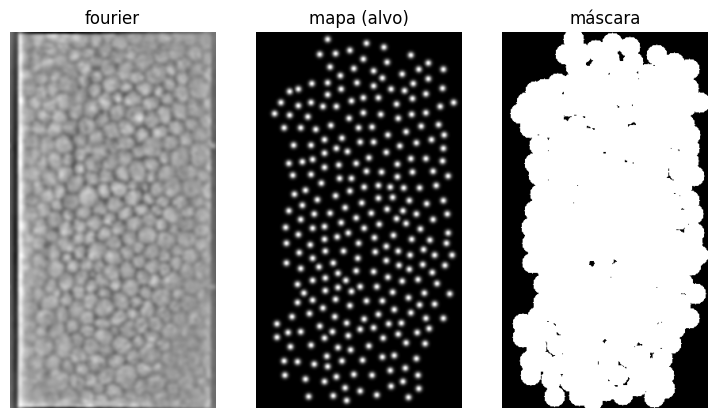

In [ ]:
def gerar_mapa(forma, centros, esp):
    sigma = esp / 6                           # mancha menor que a célula
    yy, xx = np.mgrid[:forma[0], :forma[1]]
    mapa = np.zeros(forma, np.float32)
    for x, y in centros[['x', 'y']].to_numpy(float):
        mapa = np.maximum(mapa, np.exp(-((xx - x)**2 + (yy - y)**2) / (2 * sigma**2)))
    return mapa

def gerar_mascara(forma, centros, esp):
    mascara = np.zeros(forma, np.uint8)
    for x, y in centros[['x', 'y']].to_numpy(int):
        cv2.circle(mascara, (int(x), int(y)), int(esp * 0.8), 1, -1)
    return mascara

mapa = gerar_mapa(img.shape, centros, esp)
mascara = gerar_mascara(img.shape, centros, esp)

fig, eixos = plt.subplots(1, 3, figsize=(9, 6))
for ax, (nome, im) in zip(eixos, [('fourier', fourier_passa_banda(img, esp)), ('mapa (alvo)', mapa), ('máscara', mascara)]):
    ax.imshow(im, cmap='gray')
    ax.set_title(nome)
    ax.axis('off')
plt.show()

Mapa: uma mancha em cada célula anotada, todas separadas. Isso mostra que o tamanho da mancha (esp/6) está bom.

Máscara: cobre a região anotada. As bordas da imagem e a faixa sem anotação ficam de fora, então a U-Net não vai ser “cobrada” lá.

In [ ]:
validos = [(i, t) for i, t in pares
           if ' (' not in i.name and len(ler_centros(t)) >= 3]

treino, resto = train_test_split(validos, test_size=0.30, random_state=SEED)
val, teste = train_test_split(resto, test_size=0.50, random_state=SEED)

print(len(validos), 'imagens válidas →', len(treino), 'treino |', len(val), 'validação |', len(teste), 'teste')

323 imagens válidas → 226 treino | 48 validação | 49 teste


In [ ]:
(PROCESSADO / 'imagens').mkdir(exist_ok=True)
(PROCESSADO / 'alvos').mkdir(exist_ok=True)

registro = []
for grupo, lista in (('treino', treino), ('val', val), ('teste', teste)):
    for img_path, txt_path in lista:
        img = carregar_imagem(img_path)
        centros = ler_centros(txt_path)
        esp = espacamento_medio(centros)
        nome = img_path.stem

        cv2.imwrite(str(PROCESSADO / 'imagens' / f'{nome}.png'), fourier_passa_banda(img, esp))
        np.savez_compressed(PROCESSADO / 'alvos' / f'{nome}.npz',
                            mapa=gerar_mapa(img.shape, centros, esp),
                            mascara=gerar_mascara(img.shape, centros, esp))
        registro.append({'nome': nome, 'grupo': grupo, 'espacamento': esp, 'n_centros': len(centros)})

divisao = pd.DataFrame(registro)
divisao.to_csv(PROCESSADO / 'divisao.csv', index=False)
display(divisao['grupo'].value_counts())

,count
grupo,
treino,226
teste,49
val,48
